#Evironment setup and dataset loading
Dataset: [text](https://www.youtube.com/redirect?event=video_description&redir_token=QUM4Zm9rUXBsZDhIUzFuejVWWWltb2lWZWNOSnxBR3JiS2FrbFlSZllrbXlINUREeGsyOHpOZUI0QnhnOFZSeWRMSDZWN29MRUdHdjFXQVhSTEhPR3pVSGFlNVI2WVk4MTM4Mlk1aXEyWWIzUklhcHN6ejhscV9VbXRVenk1R1V2&q=https%3A%2F%2Fwww.kaggle.com%2Fdatasets%2Fbirdy654%2Fcifake-real-and-ai-generated-synthetic-images&v=yf3rcJQG2Bg)

In [1]:
import os
from IPython.display import Image, display, clear_output
#Define kaggel API and keys from json data
%pip install kaggle
import kagglehub
path = kagglehub.dataset_download("birdy654/cifake-real-and-ai-generated-synthetic-images")
print("Path to dataset:", path)


  Using cached kaggle-2.2.4-py3-none-any.whl.metadata (17 kB)
  Using cached bleach-6.4.0-py3-none-any.whl.metadata (32 kB)
  Using cached jupytext-1.19.5-py3-none-any.whl.metadata (15 kB)
  Using cached python_dotenv-1.2.3-py3-none-any.whl.metadata (29 kB)
  Using cached python_slugify-8.0.4-py2.py3-none-any.whl.metadata (8.5 kB)
  Using cached webencodings-0.6.1-py3-none-any.whl.metadata (3.4 kB)
  Using cached mdit_py_plugins-0.6.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
  Using cached fastjsonschema-2.22.2-py3-none-any.whl.metadata (2.1 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached text_unidecode-1.3-py2.py3-none-any.whl.metadata (2.4 kB)
Using cached kaggle-2.2.4-py3-

c:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset: C:\Users\ayush\.cache\kagglehub\datasets\birdy654\cifake-real-and-ai-generated-synthetic-images\versions\3


DATA EXTRACTION CLEANUP


In [ ]:
import random
import shutil
DATA_ROOT = r'C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake-real-and-ai-generated-synthetic-images\versions\3'
train_path = os.path.join(DATA_ROOT, 'train')
validation_path = os.path.join(DATA_ROOT, 'test')
#Define split size - Move 10,000 images per class
VALIDATION_SAMPLE_PER_CLASS = 10000
print("Train path:", train_path)
print("Validation path:", validation_path)
os.makedirs(os.path.join(validation_path, 'real'), exist_ok=True)
os.makedirs(os.path.join(validation_path, 'fake'), exist_ok=True)
# perform the split 
real_train_images= os.listdir(os.path.join(train_path, 'real'))
fake_train_images= os.listdir(os.path.join(train_path, 'fake'))
real_validation_images = os.listdir(os.path.join(validation_path, 'real'))
fake_validation_images = os.listdir(os.path.join(validation_path, 'fake'))
real_images = os.listdir(os.path.join(train_path, 'real'))
random.shuffle(real_images)

#selecr the specified number of images for validation
images_to_move = real_images[:VALIDATION_SAMPLE_PER_CLASS]
for image in images_to_move:
    shutil.move(
        os.path.join(train_path, 'real', image),
        os.path.join(validation_path, 'real', image)
    )

fake_images = os.listdir(os.path.join(train_path, 'fake'))
random.shuffle(fake_images)

#selecr the specified number of images for validation
images_to_move = fake_images[:VALIDATION_SAMPLE_PER_CLASS]
for image in images_to_move:
    shutil.move(
        os.path.join(train_path, 'fake', image),
        os.path.join(validation_path, 'fake', image)
    )

#finla count varification
print("Number of real images in train set:", len(os.listdir(os.path.join(train_path, 'real'))))
print("Number of fake images in train set:", len(os.listdir(os.path.join(train_path, 'fake'))))
print("Number of real images in validation set:", len(os.listdir(os.path.join(validation_path, 'real'))))
print("Number of fake images in validation set:", len(os.listdir(os.path.join(validation_path, 'fake'))))

test_path = os.path.join(DATA_ROOT, 'test')
os.makedirs(os.path.join(test_path, 'real'), exist_ok=True)
os.makedirs(os.path.join(test_path, 'fake'), exist_ok=True)


Train path: C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake-real-and-ai-generated-synthetic-images\versions\3\train
Validation path: C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake-real-and-ai-generated-synthetic-images\versions\3\test
Number of real images in train set: 0
Number of fake images in train set: 10000
Number of real images in validation set: 50000
Number of fake images in validation set: 50000


In [16]:
print (validation_path)

C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake-real-and-ai-generated-synthetic-images\versions\3\test


In [17]:
print (test_path)

C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake-real-and-ai-generated-synthetic-images\versions\3\test


#visualisation

In [ ]:
import matplotlib.pyplot as plt
import random
from PIL import Image
TRAIN_FAKE_DIR = os.path.join(DATA_ROOT, 'train/FAKE')
TRAIN_REAL_DIR = os.path.join(DATA_ROOT, 'train/REAL')
#Get a list of all filenames in each directory
fake_files = os.listdir (TRAIN_FAKE_DIR)
real_files = os.listdir (TRAIN_REAL_DIR)
# Select a few random images to display
num_samples = 8
random_fake = random.sample(fake_files, num_samples // 2)
random_real = random.sample(real_files, num_samples // 2)
fig, axes = plt.subplots (2, num_samples // 2, figsize=(12, 6))
fig.suptitle("Sample CIFAKE Images (Top: FAKE, Bottom: REAL)", fontsize=16)
# Display FAKE Images
for i, filename in enumerate(random_fake):
    img_path = os.path.join(TRAIN_FAKE_DIR, filename)
    img = Image.open(img_path)
    axes [0, i].imshow(img)
    axes [0, i].set_title(f"FAKE({img.size[0]} x {img.size[1]})", fontsize = 8)
    axes [0, i].axis('off')
# Display REAL Images
for i, filename in enumerate(random_real):
    img_path = os.path.join(TRAIN_REAL_DIR, filename)
    img = Image.open(img_path)
    axes [1, i].imshow(img)
    axes [1, i].set_title(f"REAL({img.size[0]} x {img.size[1]})", fontsize = 8)
    axes [1, i].axis('off')
plt.tight_layout(rect=[0, 0.3, 1, 0.95])
plt.show()

ValueError: No real images found in C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake-real-and-ai-generated-synthetic-images\versions\3\train\real. Check the dataset folder names.

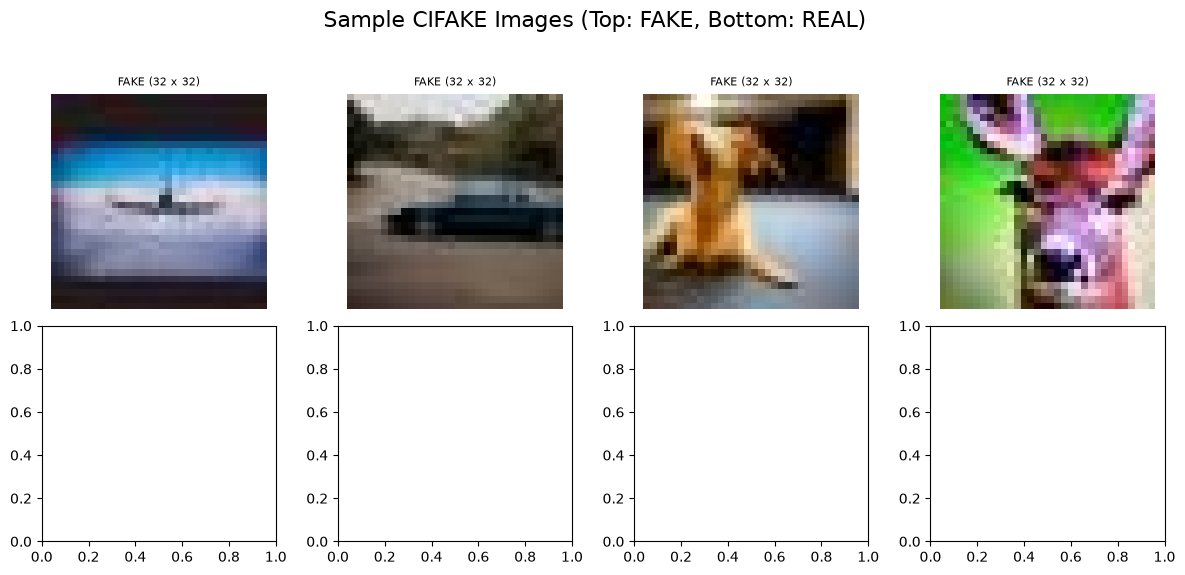

In [5]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

TRAIN_FAKE_DIR = os.path.join(DATA_ROOT, 'train/FAKE')
TRAIN_REAL_DIR = os.path.join(DATA_ROOT, 'train/REAL')

fake_files = os.listdir(TRAIN_FAKE_DIR)
real_files = os.listdir(TRAIN_REAL_DIR)

num_samples = 8
k = num_samples // 2

# Safely sample up to available file count
random_fake = random.sample(fake_files, min(k, len(fake_files)))
random_real = random.sample(real_files, min(k, len(real_files)))

fig, axes = plt.subplots(2, k, figsize=(12, 6))
fig.suptitle("Sample CIFAKE Images (Top: FAKE, Bottom: REAL)", fontsize=16)

# Display FAKE Images
for i, filename in enumerate(random_fake):
    img_path = os.path.join(TRAIN_FAKE_DIR, filename)
    img = Image.open(img_path)
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"FAKE ({img.size[0]} x {img.size[1]})", fontsize=8)
    axes[0, i].axis('off')

# Display REAL Images
for i, filename in enumerate(random_real):
    img_path = os.path.join(TRAIN_REAL_DIR, filename)
    img = Image.open(img_path)
    axes[1, i].imshow(img)
    axes[1, i].set_title(f"REAL ({img.size[0]} x {img.size[1]})", fontsize=8)
    axes[1, i].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [18]:


import tensorflow as tf
import os

# DATASET CONFIG PARAMETERS
IMG_SIZE = 32
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
SEED = 42
DATA_ROOT = r'C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake\versions\3'

# DIRECTORY PATHS
TRAIN_DIR = os.path.join(DATA_ROOT, 'train')
VALIDATION_DIR = os.path.join(DATA_ROOT, 'test')
TEST_DIR = os.path.join(DATA_ROOT, 'test')

# Load training Data ( Raw 0 -255 pixels)
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    label_mode = 'binary',
    seed = SEED,
    image_size = (IMG_SIZE, IMG_SIZE),
    batch_size = BATCH_SIZE,
    shuffle = True
)

# Load Validation Data (Raw 0 -255 pixels)
val_ds = tf.keras.utils.image_dataset_from_directory(
    VALIDATION_DIR,
    label_mode = 'binary',
    seed = SEED,
    image_size = (IMG_SIZE, IMG_SIZE),
    batch_size = BATCH_SIZE,
    shuffle = False
)

# Load Test Data (Raw 0 -255 pixels)
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    label_mode = 'binary',
    seed = SEED,
    image_size = (IMG_SIZE, IMG_SIZE),
    batch_size = BATCH_SIZE,
    shuffle = False
)

#Normalize and AUTOTUNE
AUTOTUNE = tf.data.AUTOTUNE
#Apply caching and prefetching to RAW Datasets for performance
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)
#Print
print('Datasets Loaded in Raw format, ready for rescaling')

Found 10000 files belonging to 2 classes.
Found 100000 files belonging to 2 classes.
Found 100000 files belonging to 2 classes.
Datasets Loaded in Raw format, ready for rescaling


In [19]:

from tensorflow import keras
from tensorflow.keras import layers
# Define the CNN architecture
inputs = keras.Input (shape = (32,32,3))
x = layers. Rescaling(1./255) (inputs)
x = layers. Conv2D(filters = 32, kernel_size = 3, activation = 'relu') (x)
x = layers.MaxPooling2D(pool_size = 2)(x)
x = layers.Conv2D(filters = 32, kernel_size = 3, activation = 'relu') (x)
x = layers.MaxPooling2D(pool_size = 2)(x)
x = layers. Flatten()(x)
x = layers. Dropout(0.5)(x)
x = layers. Dense (64, activation = 'relu') (x)
x = layers. Dropout(0.5)(x)
outputs = layers. Dense (1, activation = 'sigmoid')(x)
# Create the model
model = keras. Model(inputs = inputs, outputs = outputs)

In [20]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,001 (328.13 KB)

 Trainable params: 84,001 (328.13 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
from tensorflow.keras.utils import image_dataset_from_directory
batchsize = 512
train_dataset = image_dataset_from_directory(
r"C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake\versions\3\train"
,image_size=(32,32)
,batch_size=batchsize
)
validation_dataset = image_dataset_from_directory(
r"C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake\versions\3\test"

,image_size=(32,32)
,batch_size=batchsize
)
test_dataset = image_dataset_from_directory(
r"C:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\cifake\versions\3\test"

,image_size=(32,32)
,batch_size=batchsize
)

Found 10000 files belonging to 2 classes.
Found 100000 files belonging to 2 classes.
Found 100000 files belonging to 2 classes.


In [23]:
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [ ]:
callbacks = [
keras.callbacks.ModelCheckpoint (
filepath = 'convnet_from_scratch.keras',
save_best_only = True,
monitor = 'val_loss'
)
]
history = model.fit(
train_dataset,
epochs = 150,
validation_data = validation_dataset,
callbacks = callbacks
)


Epoch 1/150


c:\Users\ayush\OneDrive\Documents\SEM5\DL\CP\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


20/20 ━━━━━━━━━━━━━━━━━━━━ 216s 10s/step - accuracy: 0.9671 - loss: 0.1062 - val_accuracy: 0.5000 - val_loss: 14.5359
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 111s 6s/step - accuracy: 1.0000 - loss: 1.1201e-08 - val_accuracy: 0.5000 - val_loss: 21.6610
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 90s 5s/step - accuracy: 1.0000 - loss: 4.0851e-09 - val_accuracy: 0.5000 - val_loss: 22.9303
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 1.0000 - loss: 1.1903e-08

In [ ]:
import matplotlib.pyplot as plt

from profiling.tracing import label
def plot_loss_acc_training (history):
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range (1, len (accuracy) + 1)
plt.plot(epochs, accuracy, 'bo', label = "Training Accuracy")
plt.plot(epochs, val_accuracy, 'ro', label = "Validation Accuracy")
plt.title('Training and Validation Accuracy')
plt.legend()
plt.figure()
plt.plot(epochs, loss, 'bo', label = "Training Loss")
plt.plot(epochs, val_loss, 'ro', label = "Validation Loss")
plt.title('Training and Validation Loss')
plt.legend()
plt.show()